# Unit 2 – Practical Work: MNIST Image Classification with a CNN (PyTorch)

**Workshop – Dr. Amel BOUCHEMHA – NHSM**

**Objectives**
- Master the PyTorch ecosystem (`torch.nn`, `torch.optim`, `DataLoader`)
- Implement convolutional and pooling layers
- Write a complete training loop from scratch
- Evaluate a multiclass classifier: confusion matrix, accuracy, precision, recall, F1-score and ROC-AUC

**Dataset:** MNIST – 60,000 training and 10,000 test grayscale images (28×28) of handwritten digits 0–9.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.preprocessing import label_binarize

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 1 – Data Preparation and Exploration
- Convert images to tensors and normalize pixel values (MNIST mean = 0.1307, std = 0.3081)
- Create the training and test `DataLoader`s with a batch size of 64
- Plot 5 random images from a training batch with their ground-truth labels

In [2]:
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.ToTensor(),                        # [0,255] -> [0,1], shape (1, 28, 28)
    transforms.Normalize((0.1307,), (0.3081,))    # standardize with MNIST statistics
])

# Downloads MNIST into ./data the first time (needs internet).
# If you already downloaded it (e.g. from Kaggle), put it in ./data/MNIST/raw and keep download=True.
train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print("Training samples:", len(train_dataset))
print("Test samples    :", len(test_dataset))
print("Batches per epoch (train):", len(train_loader))

Training samples: 60000
Test samples    : 10000
Batches per epoch (train): 938


Batch shape: torch.Size([64, 1, 28, 28]) | Labels shape: torch.Size([64])


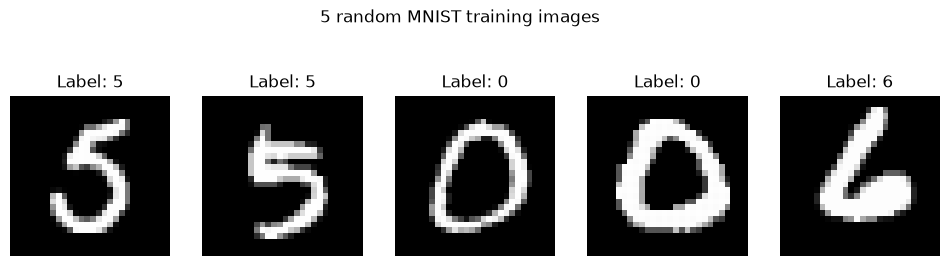

In [3]:
# Take one training batch and plot 5 random images from it
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape, "| Labels shape:", labels.shape)

idx = random.sample(range(images.size(0)), 5)
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, i in zip(axes, idx):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.suptitle("5 random MNIST training images", y=1.05)
plt.show()

## Step 2 – Designing the CNN Architecture (`CNNMNIST`)

| Block | Layers | Output shape |
|---|---|---|
| Input | – | 1 × 28 × 28 |
| Conv block 1 | Conv2d(1→32, 3×3, stride 1, no padding) → ReLU → MaxPool(2×2, stride 2) | 32 × 13 × 13 |
| Conv block 2 | Conv2d(32→64, 3×3, stride 1, no padding) → ReLU → MaxPool(2×2, stride 2) | 64 × 5 × 5 |
| Classification | Flatten (1600) → Linear(1600→128) → ReLU → Linear(128→10) | 10 |

Spatial size formula: `out = (in − kernel + 2·padding) / stride + 1`
→ 28 → 26 (conv) → 13 (pool) → 11 (conv) → 5 (pool, floor of 5.5).

In [4]:
class CNNMNIST(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Convolutional Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Convolutional Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Classification Block
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 5 * 5, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)      # raw logits (Softmax is inside CrossEntropyLoss)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return self.classifier(x)

# Sanity check: trace the shape through every stage
model_test = CNNMNIST()
x = torch.randn(1, 1, 28, 28)
print("Input           :", tuple(x.shape))
x = model_test.block1(x);  print("After block 1   :", tuple(x.shape))
x = model_test.block2(x);  print("After block 2   :", tuple(x.shape))
x = model_test.classifier(x); print("Output (logits) :", tuple(x.shape))

n_params = sum(p.numel() for p in model_test.parameters())
print(f"\nTotal trainable parameters: {n_params:,}")
print(model_test)

Input           : (1, 1, 28, 28)
After block 1   : (1, 32, 13, 13)
After block 2   : (1, 64, 5, 5)
Output (logits) : (1, 10)

Total trainable parameters: 225,034
CNNMNIST(
  (block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## Step 3 – Configuration and Training Loop
- Detect GPU (`cuda` or `mps`) and move the model to it
- Loss: Cross-Entropy | Optimizer: Adam, learning rate 0.001
- Train for 5 epochs: reset gradients → forward → loss → backprop → update weights
- Display average loss and accuracy after each epoch

In [5]:
# Hardware configuration
if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device:", device)

model = CNNMNIST().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5

Using device: cpu


In [6]:
def evaluate_loss_acc(model, loader):
    """Average loss and accuracy of the model on a DataLoader (no gradient)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            total_loss += criterion(out, y).item() * X.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total


history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()              # 1. reset gradients
        outputs = model(X)                 # 2. forward pass
        loss = criterion(outputs, y)       # 3. compute loss
        loss.backward()                    # 4. backpropagation
        optimizer.step()                   # 5. update weights

        running_loss += loss.item() * X.size(0)
        correct += (outputs.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    train_loss, train_acc = running_loss / total, correct / total
    test_loss, test_acc = evaluate_loss_acc(model, test_loader)

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss);   history["test_acc"].append(test_acc)

    print(f"Epoch {epoch}/{EPOCHS} | "
          f"Train loss: {train_loss:.4f}  acc: {train_acc*100:.2f}% | "
          f"Test loss: {test_loss:.4f}  acc: {test_acc*100:.2f}%")

Epoch 1/5 | Train loss: 0.1362  acc: 95.87% | Test loss: 0.0430  acc: 98.53%
Epoch 2/5 | Train loss: 0.0446  acc: 98.56% | Test loss: 0.0309  acc: 98.99%
Epoch 3/5 | Train loss: 0.0296  acc: 99.08% | Test loss: 0.0362  acc: 98.83%
Epoch 4/5 | Train loss: 0.0218  acc: 99.31% | Test loss: 0.0302  acc: 99.16%
Epoch 5/5 | Train loss: 0.0176  acc: 99.42% | Test loss: 0.0304  acc: 98.96%


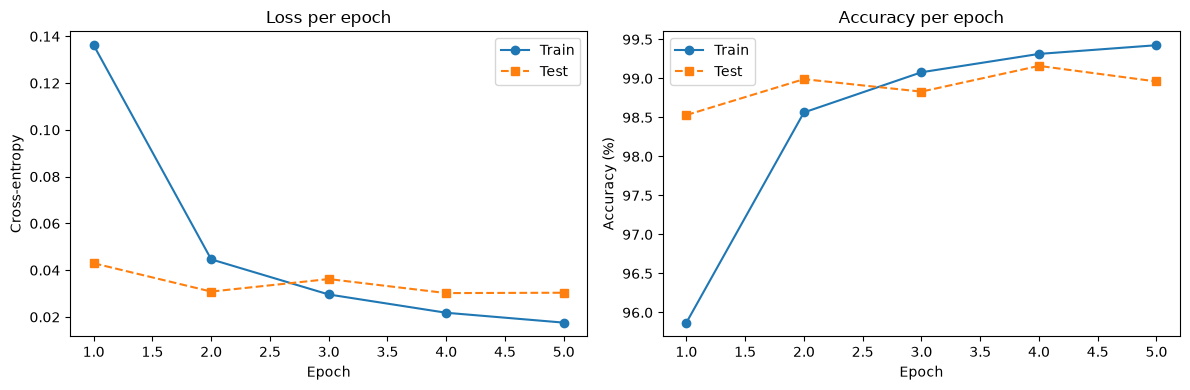

In [7]:
# Learning curves
epochs_range = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs_range, history["train_loss"], "o-", label="Train")
ax[0].plot(epochs_range, history["test_loss"],  "s--", label="Test")
ax[0].set_title("Loss per epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy"); ax[0].legend()

ax[1].plot(epochs_range, [a*100 for a in history["train_acc"]], "o-", label="Train")
ax[1].plot(epochs_range, [a*100 for a in history["test_acc"]],  "s--", label="Test")
ax[1].set_title("Accuracy per epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].legend()

plt.tight_layout(); plt.show()

## Step 4 – Evaluation and Error Analysis
Metrics on the test set: **Accuracy, Precision, Recall, F1-score, ROC-AUC**, plus the **confusion matrix**.
Precision / Recall / F1 are reported with *macro* averaging (each class weighs the same) and per class.
ROC-AUC uses the one-vs-rest strategy on the softmax probabilities.

In [8]:
# Collect predictions and class probabilities on the whole test set
model.eval()
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        logits = model(X)
        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.append(logits.argmax(dim=1).cpu().numpy())
        all_labels.append(y.numpy())

y_pred = np.concatenate(all_preds)
y_true = np.concatenate(all_labels)
y_prob = np.concatenate(all_probs)

# Global metrics
acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, average="macro")
rec  = recall_score(y_true, y_pred, average="macro")
f1   = f1_score(y_true, y_pred, average="macro")
roc  = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")

print("=== Test-set metrics (macro average) ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc:.4f}  (one-vs-rest)")

print("\n=== Per-class report ===")
print(classification_report(y_true, y_pred, digits=4))

=== Test-set metrics (macro average) ===
Accuracy : 0.9896
Precision: 0.9895
Recall   : 0.9896
F1-score : 0.9895
ROC-AUC  : 0.9999  (one-vs-rest)

=== Per-class report ===
              precision    recall  f1-score   support

           0     0.9829    0.9980    0.9904       980
           1     0.9965    0.9938    0.9951      1135
           2     0.9941    0.9797    0.9868      1032
           3     0.9921    0.9921    0.9921      1010
           4     0.9878    0.9929    0.9904       982
           5     0.9888    0.9877    0.9882       892
           6     0.9958    0.9906    0.9932       958
           7     0.9817    0.9903    0.9860      1028
           8     0.9877    0.9897    0.9887       974
           9     0.9880    0.9812    0.9846      1009

    accuracy                         0.9896     10000
   macro avg     0.9895    0.9896    0.9895     10000
weighted avg     0.9896    0.9896    0.9896     10000



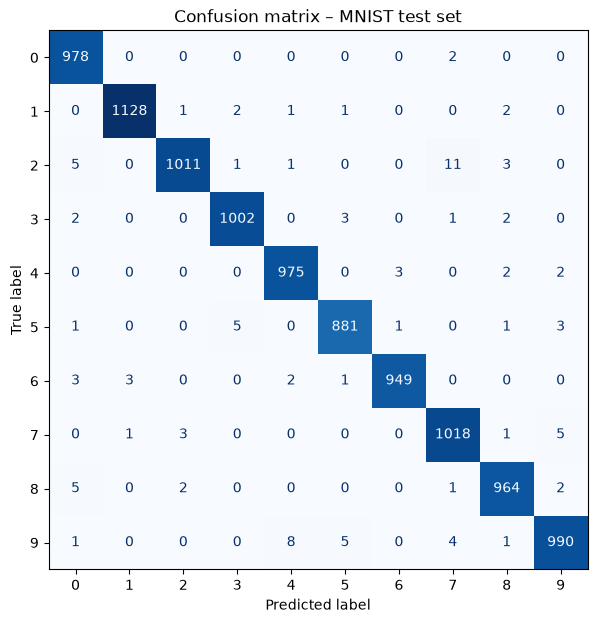

In [9]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix – MNIST test set")
plt.show()

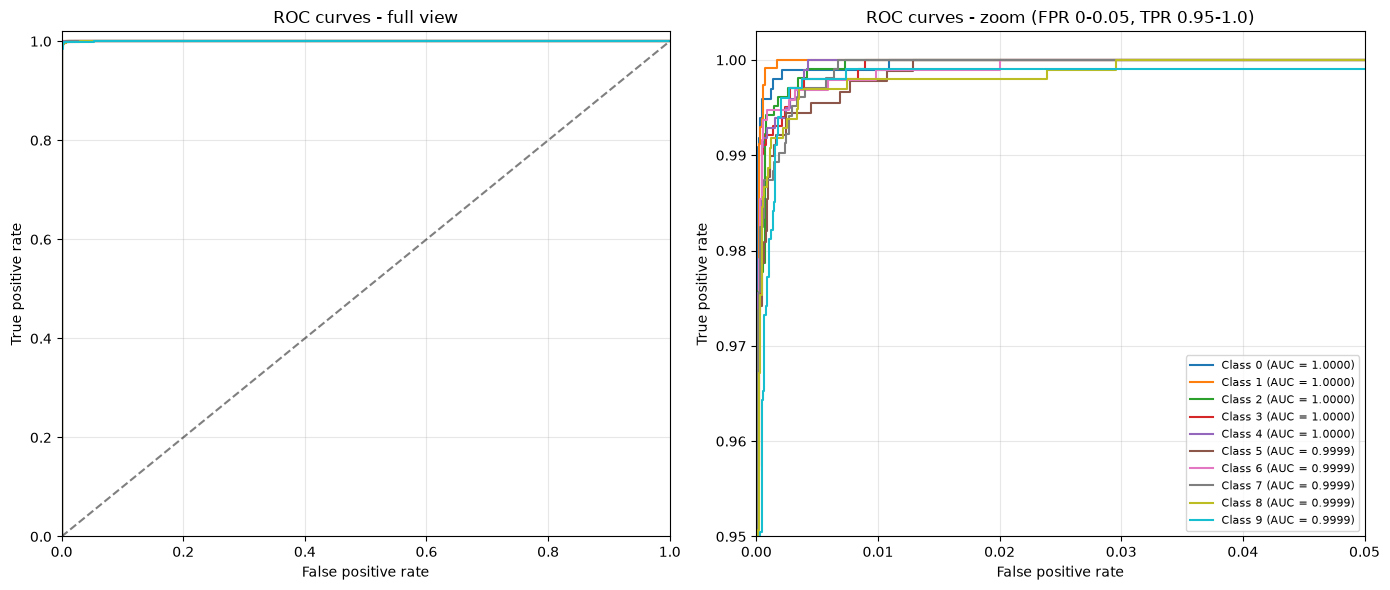

In [10]:
# ROC curves (one-vs-rest) for the 10 classes: full view + zoomed view
y_true_bin = label_binarize(y_true, classes=list(range(10)))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for c in range(10):
    fpr, tpr, _ = roc_curve(y_true_bin[:, c], y_prob[:, c])
    label = f"Class {c} (AUC = {auc(fpr, tpr):.4f})"
    axes[0].plot(fpr, tpr, label=label)
    axes[1].plot(fpr, tpr, label=label)

# Left: full view
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.02)
axes[0].set_title("ROC curves - full view")

# Right: zoom on the top-left corner where the curves actually differ
axes[1].set_xlim(0, 0.05); axes[1].set_ylim(0.95, 1.003)
axes[1].set_title("ROC curves - zoom (FPR 0-0.05, TPR 0.95-1.0)")

for ax in axes:
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()


Top 5 confusions (true -> predicted : count)
  2 -> 7 : 11
  9 -> 4 : 8
  9 -> 5 : 5
  7 -> 9 : 5
  5 -> 3 : 5

Total misclassified: 104 / 10000


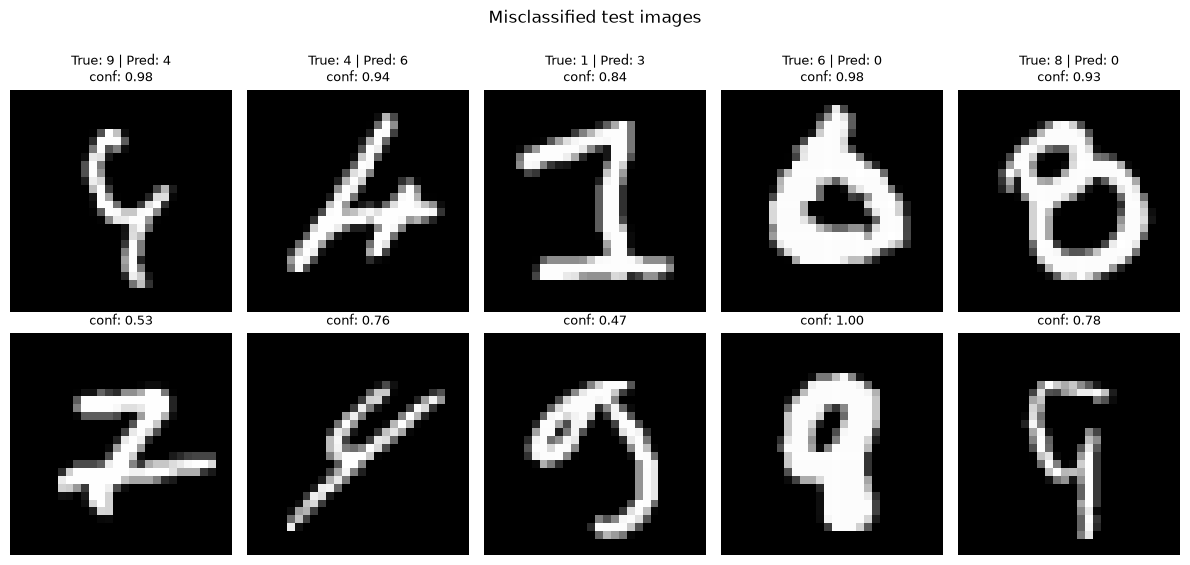

In [11]:
# Error analysis: most frequent confusions + examples of misclassified digits
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
print("Top 5 confusions (true -> predicted : count)")
for t, p in top:
    print(f"  {t} -> {p} : {cm_off[t, p]}")

wrong_idx = np.where(y_pred != y_true)[0]
print(f"\nTotal misclassified: {len(wrong_idx)} / {len(y_true)}")

sample = np.random.choice(wrong_idx, size=min(10, len(wrong_idx)), replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, i in zip(axes.ravel(), sample):
    img, _ = test_dataset[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"True: {y_true[i]} | Pred: {y_pred[i]}\nconf: {y_prob[i, y_pred[i]]:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified test images", y=1.02)
plt.tight_layout(); plt.show()